---

# Extract.py

In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))   # notebooks/ 의 상위 = 프로젝트 루트 (src 를 찾기 위함)

from src.extract import extract_pdf_elements, categorize_elements, PROJECT_ROOT, fpath, fname

In [2]:
# 함수 실행 (hi_res 추출은 2~3분 소요)
raw_pdf_elements = extract_pdf_elements(fpath, fname)
texts, tables = categorize_elements(raw_pdf_elements)
print("전체 요소:", len(raw_pdf_elements), "/ 텍스트:", len(texts), "/ 표:", len(tables))

Thank you for using Unstructured Open Source! Try Unstructured's commercial offering for improved output quality. 10,000 free pages to start. Learn more: https://transform.unstructured.io/?utm_source=unstructured_oss Hide this notice: UNSTRUCTURED_DISABLE_NOTICE=1
Ignoring wrong pointing object 2 65536 (offset 0)
Ignoring wrong pointing object 57 65536 (offset 0)
Ignoring wrong pointing object 88 65536 (offset 0)
Ignoring wrong pointing object 119 65536 (offset 0)
Ignoring wrong pointing object 135 65536 (offset 0)
Ignoring wrong pointing object 138 65536 (offset 0)
Ignoring wrong pointing object 141 65536 (offset 0)
Ignoring wrong pointing object 144 65536 (offset 0)
Ignoring wrong pointing object 147 65536 (offset 0)
Ignoring wrong pointing object 182 65536 (offset 0)
Ignoring wrong pointing object 198 65536 (offset 0)
Ignoring wrong pointing object 208 65536 (offset 0)
Ignoring wrong pointing object 244 65536 (offset 0)
Ignoring wrong pointing object 253 65536 (offset 0)
Ignoring wr

전체 요소: 13 / 텍스트: 7 / 표: 6


In [3]:
from collections import Counter

for etype, cnt in Counter(type(el).__name__ for el in raw_pdf_elements).most_common():
    print(f"{etype:20s}: {cnt}개")
figures_dir = Path(fpath) / "figures"
image_files = sorted(f for f in figures_dir.iterdir()
                        if f.suffix.lower() in (".jpg", ".jpeg", ".png"))
print("추출된 이미지:", len(image_files), "개")

CompositeElement    : 7개
Table               : 6개
추출된 이미지: 10 개


In [4]:
# 텍스트 재분할(토큰 기준 2000, 겹침 200) + extracted.pkl 저장  ← extract.py [6][7] 단계
import pickle
from langchain_text_splitters import CharacterTextSplitter

text_splitter = CharacterTextSplitter.from_tiktoken_encoder(chunk_size=2000, chunk_overlap=200)
texts_2k_token = text_splitter.split_text(" ".join(texts))     # 블록을 합친 뒤 균일하게 재분할
print("분할 후 블록 수:", len(texts_2k_token))

output_dir = PROJECT_ROOT / "data" / "processed"
output_dir.mkdir(parents=True, exist_ok=True)
with open(output_dir / "extracted.pkl", "wb") as f:
    pickle.dump({"texts": texts, "tables": tables, "texts_2k_token": texts_2k_token}, f)
print("저장 완료:", output_dir / "extracted.pkl")

분할 후 블록 수: 4
저장 완료: c:\workspaces\part2\multimodal-rag\data\processed\extracted.pkl


---

# Summarize.py

In [ ]:
import pickle
from dotenv import load_dotenv

from src.summarize import generate_text_summaries, generate_img_summaries

load_dotenv(PROJECT_ROOT / ".env")   # OPENAI_API_KEY 를 환경변수로 등록

True

In [6]:
# 텍스트·표 요약 (LLM 호출, 비용 발생)
with open(PROJECT_ROOT / "data" / "processed" / "extracted.pkl", "rb") as f:
    data = pickle.load(f)

text_summaries, table_summaries = generate_text_summaries(
    data["texts_2k_token"], data["tables"], summarize_texts=True
)
print("텍스트 요약:", len(text_summaries), "/ 표 요약:", len(table_summaries))

텍스트 요약: 4 / 표 요약: 6


In [7]:
# 이미지 요약 (VLM 호출, 비용 발생)
img_base64_list, image_summaries = generate_img_summaries(str(PROJECT_ROOT / "data" / "figures"))
print("이미지 요약:", len(image_summaries), "장")

이미지 요약: 10 장


In [8]:
# summaries.pkl 저장  ← summarize.py [8] 단계 (요약 재생성 비용 절약)
output_dir = PROJECT_ROOT / "data" / "processed"
output_dir.mkdir(parents=True, exist_ok=True)
with open(output_dir / "summaries.pkl", "wb") as f:
    pickle.dump({
        "text_summaries": text_summaries,     # 텍스트 요약 (검색용)
        "table_summaries": table_summaries,   # 표 요약 (검색용)
        "image_summaries": image_summaries,   # 이미지 요약 (검색용)
        "img_base64_list": img_base64_list,   # 이미지 원본 (답변용, 요약과 같은 순서)
    }, f)
print("저장 완료:", output_dir / "summaries.pkl")

저장 완료: c:\workspaces\part2\multimodal-rag\data\processed\summaries.pkl


# Retriever.py

In [2]:
from src.retriever import load_processed, build_retriever, add_documents, build_chain, build_text_only_chain

In [3]:
# extracted.pkl + summaries.pkl 복원 → 요약(서랍) + 원본(서가)을 같은 doc_id 로 연결해 색인 (임베딩 API 호출, 비용 발생)
# ⚠️ 이 셀은 실행할 때마다 컬렉션을 새로 비우고 다시 색인합니다 (중복 방지)
d1, d2 = load_processed()
tables_raw, texts_2k_token = d1["tables"], d1["texts_2k_token"]
text_summaries  = d2["text_summaries"]
table_summaries = d2["table_summaries"]
image_summaries = d2["image_summaries"]
img_base64_list = d2["img_base64_list"]

retriever = build_retriever()

if text_summaries:  add_documents(retriever, text_summaries,  texts_2k_token)
if table_summaries: add_documents(retriever, table_summaries, tables_raw)
if image_summaries: add_documents(retriever, image_summaries, img_base64_list)
print("색인된 요약 수:", len(retriever.vectorstore.get()["ids"]))

색인된 요약 수: 20


In [4]:
# 멀티모달 RAG 질의 (LLM 호출, 비용 발생)
chain = build_chain(retriever)
query = "2018~2024년 사이 은행-기업 연계비율이 보험 및 연금기관-가계 연계비율과 교차(역전)한 시점은 언제이고, 2024년 두 값은?"   # 질문 내용.
answer = chain.invoke(query)
print(f"Q: {query}\n{'-'*70}\n{answer}")

Q: 2018~2024년 사이 은행-기업 연계비율이 보험 및 연금기관-가계 연계비율과 교차(역전)한 시점은 언제이고, 2024년 두 값은?
----------------------------------------------------------------------
2018~2024년 사이 은행-기업 연계비율이 보험 및 연금기관-가계 연계비율과 교차(역전)한 시점은 2021년입니다. 2024년 두 값은 은행-기업 연계비율이 12.1%이고, 보험 및 연금기관-가계 연계비율이 10.2%입니다.


In [5]:
# Before / After: 텍스트 전용 RAG 와 비교 (조건은 이미지·표 빼고 동일)
text_only_chain = build_text_only_chain(texts_2k_token)
print("[BEFORE] 텍스트 전용 RAG\n", text_only_chain.invoke(query))
print("[AFTER ] 멀티모달 RAG\n",   chain.invoke(query))

[BEFORE] 텍스트 전용 RAG
 자료에 따르면, 2018~2024년 사이 은행-기업 연계비율이 보험 및 연금기관-가계 연계비율과 교차(역전)한 시점에 대한 정보는 제공되지 않았습니다. 또한 2024년 두 값에 대한 구체적인 수치도 명시되어 있지 않습니다. 따라서 이 질문에 대한 답변은 모른다고 말씀드릴 수 있습니다.


[AFTER ] 멀티모달 RAG
 2018~2024년 사이 은행-기업 연계비율이 보험 및 연금기관-가계 연계비율과 교차(역전)한 시점은 2021년입니다. 2024년 두 값은 은행-기업 연계비율이 12.1%이고, 보험 및 연금기관-가계 연계비율이 10.2%입니다.


# 요약 비교 · 질의 5건

-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=
[9] figure-9-2.jpg


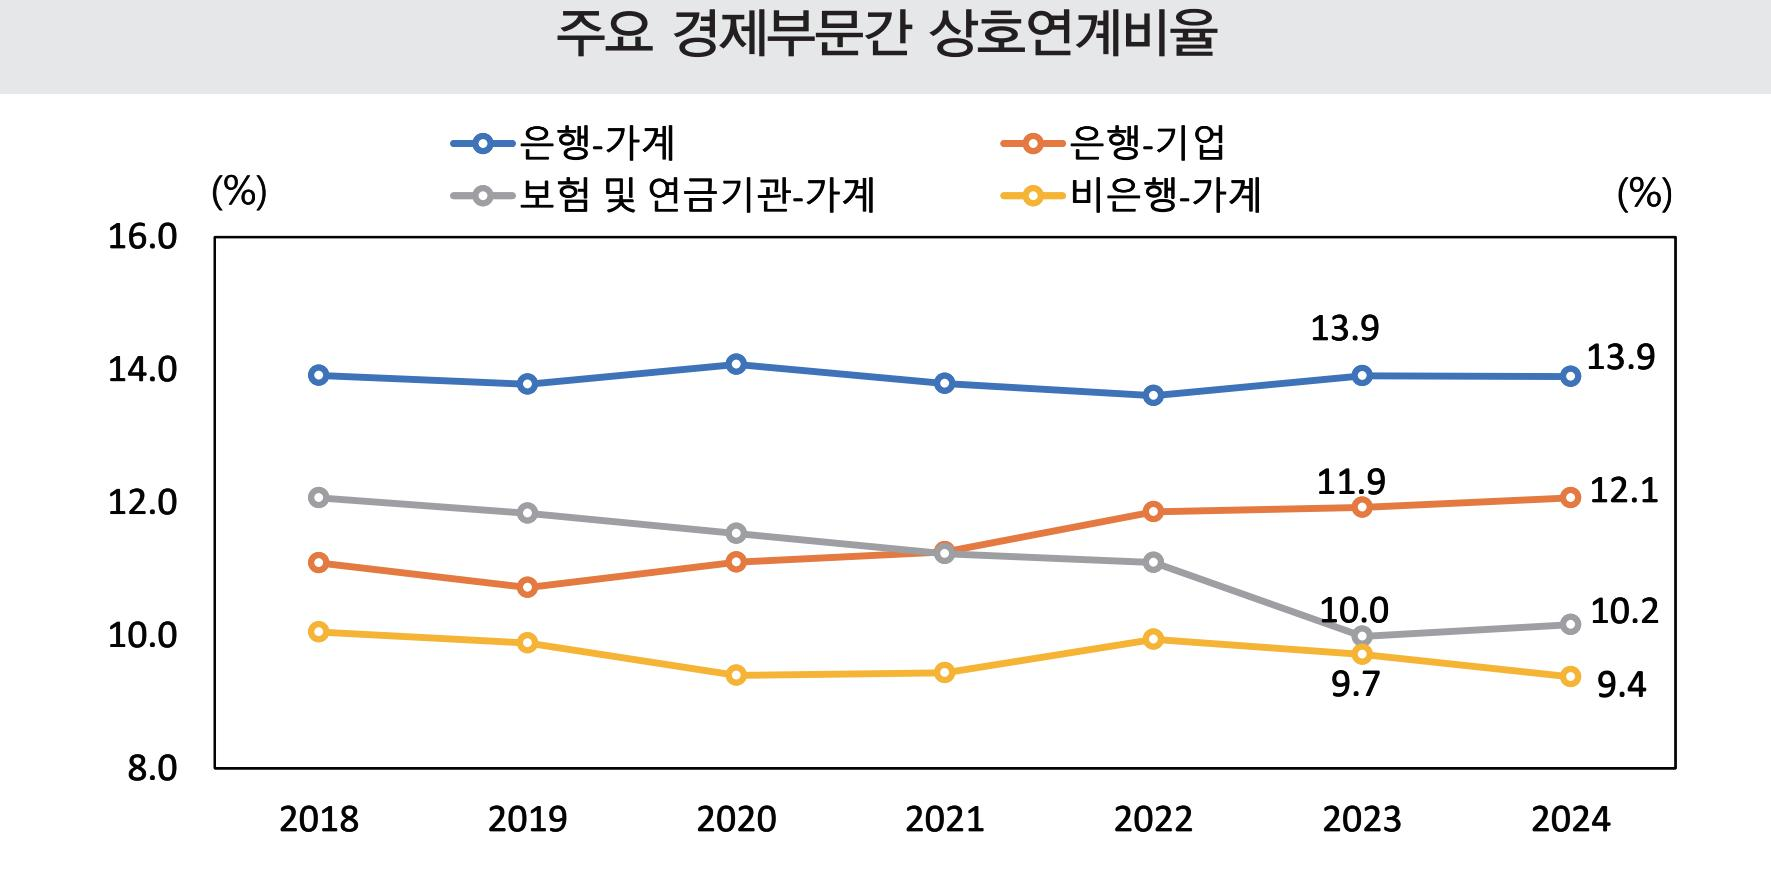

요약: 주요 경제부문 간 상호연계비율을 나타내는 그래프. 2024년 예측에 따르면, '은행-가계'와 '은행-기업'의 비율은 각각 13.9%로 동일하며, '보험 및 연금기관-가계'는 10.0%, '비은행-가계'는 9.4%로 저조한 수치를 기록. 전체적으로 은행 관련 비율이 상대적으로 높고, '비은행-가계' 부문은 감소 추세를 보임.
-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=
[3] figure-12-6.jpg


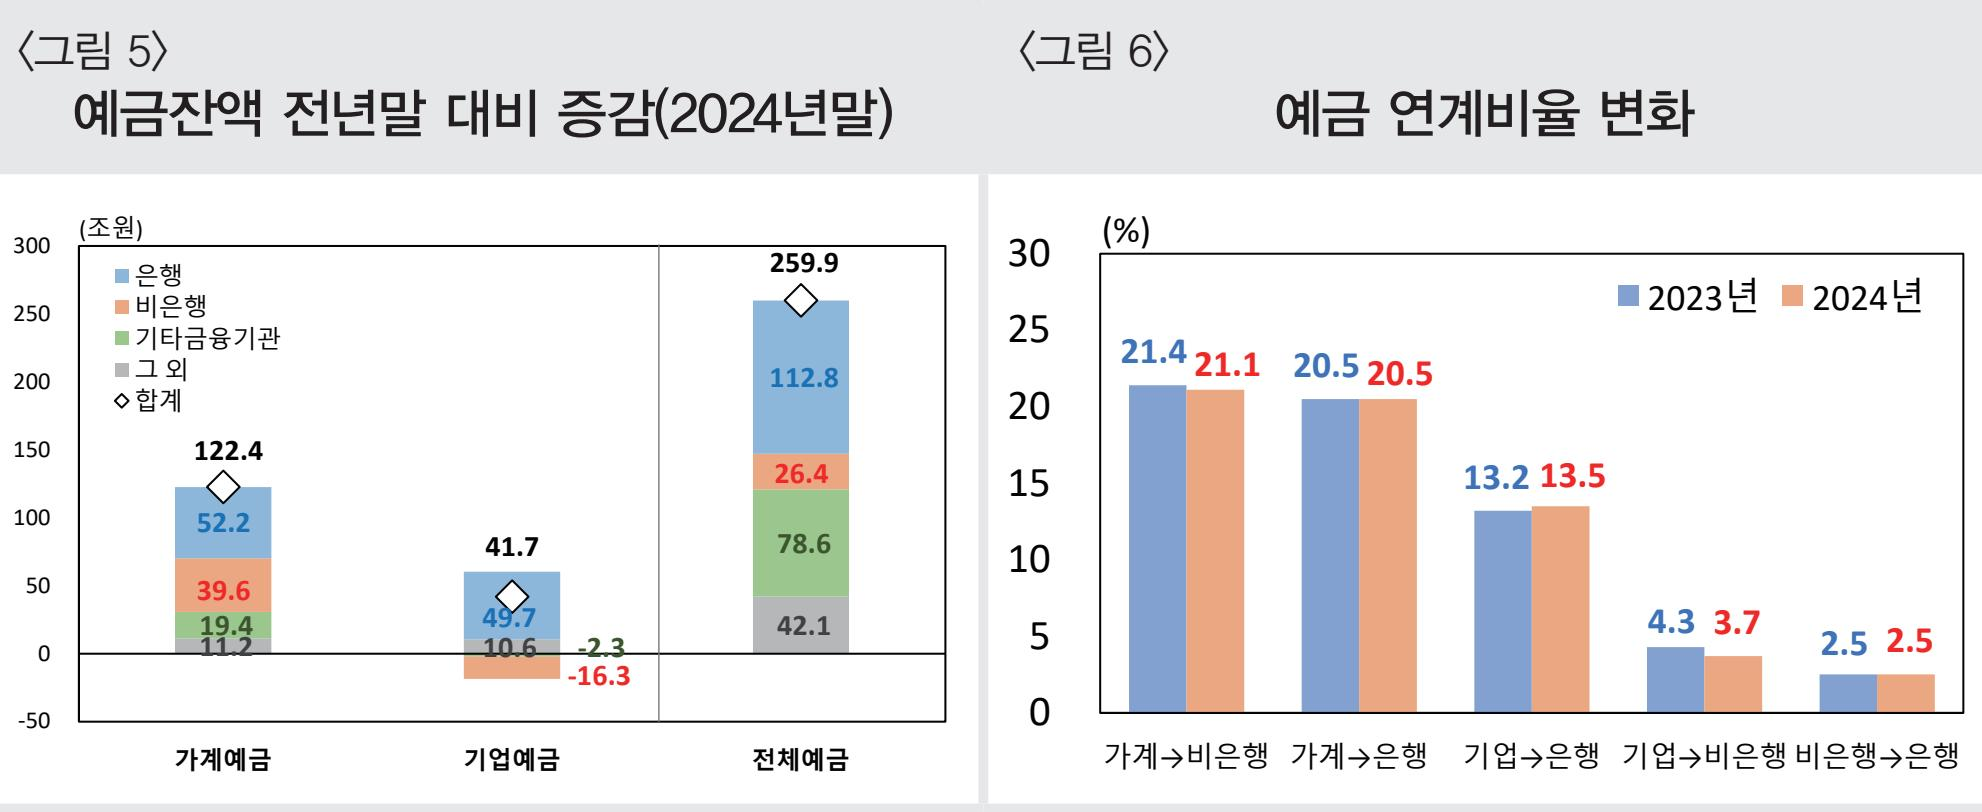

요약: 예금잔액 전년말 대비 증감(2024년말)과 예금 연계비율 변화에 대한 문서. 2024년 총 예금은 259.9조원으로, 은행(112.8조원), 기업예금(41.7조원), 기타금융기관(26.4조원) 등으로 구성됨. 예금 연계비율은 2023년과 2024년 각각 21.4%와 21.1%, 기업→은행 비율은 13.2%에서 13.5%로 증가함. 주요 트렌드는 전체 예금 증가와 특정 기관의 예금 비율 변화임.
-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=
[5] figure-15-8.jpg


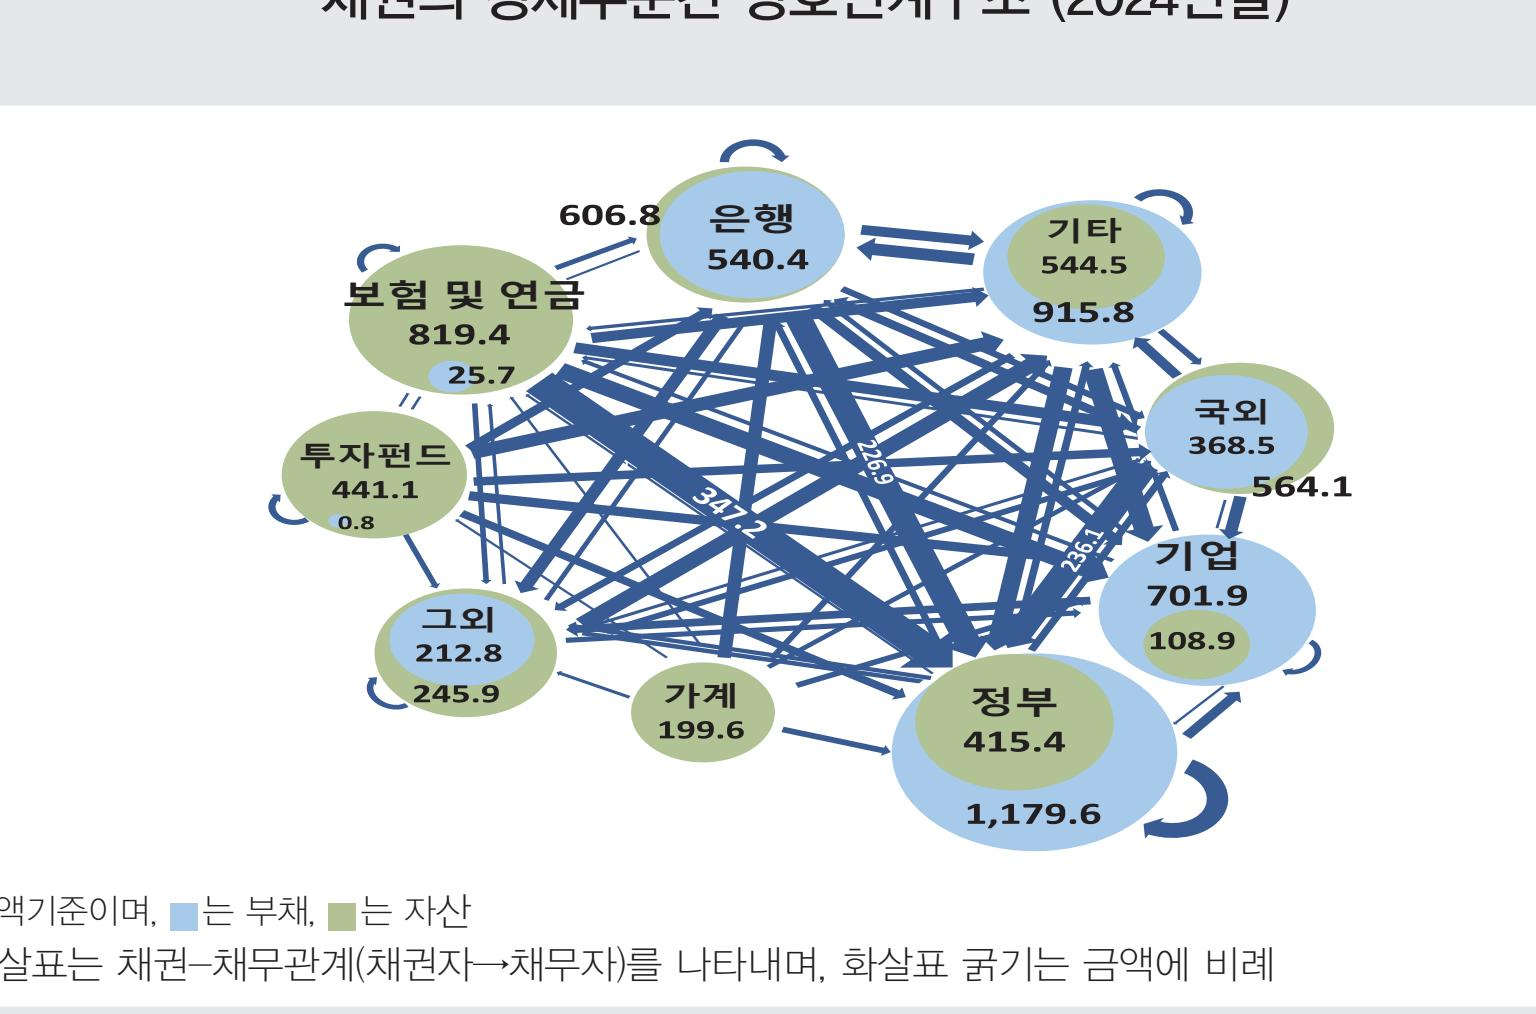

요약: 2024년 재원과 관계에 대한 도표로, 주요 항목은 정부(1,179.6), 기업(701.9), 보험 및 연금(819.4) 등이다. X/Y 축 레이블은 명시되지 않았으나, 데이터 간 연결 관계가 강조되고 있다. 특히, 정부와 그외(1,179.6 대 564.1) 간의 금융 규모가 두드러지며, 투자펀드(441.1)와의 관계도 주목할 만하다. 이 표는 채권-채무 관계를 표현하고 있다.


In [6]:
# 요약 품질 육안 검증 — 원본 그림과 이미지 요약을 나란히 (질의 5건에 쓰이는 그림 중 3장)
from IPython.display import Image, display

figures_dir = PROJECT_ROOT / "data" / "figures"
image_files = sorted(f for f in figures_dir.iterdir() if f.suffix.lower() in (".jpg", ".jpeg", ".png"))
assert len(image_files) == len(image_summaries), "그림 수와 요약 수가 다릅니다"
name_to_idx = {f.name: i for i, f in enumerate(image_files)}   # 요약·Base64 는 파일명 정렬 순서와 같다

for name in ["figure-9-2.jpg", "figure-12-6.jpg", "figure-15-8.jpg"]:
    i = name_to_idx[name]
    print("-=" * 40)
    print(f"[{i}] {name}")
    display(Image(filename=str(image_files[i]), width=450))     # 원본 그림
    print("요약:", image_summaries[i])                            # 요약 (검색용)

In [7]:
# 텍스트·표 요약 비교 — 원본 앞부분 vs 요약, 압축률(요약 길이 ÷ 원본 길이)
for kind, originals, summaries in [("텍스트", texts_2k_token, text_summaries),
                                   ("표", tables_raw, table_summaries)]:
    for i, (o, s) in enumerate(zip(originals, summaries)):
        print(f"[{kind} {i}] 원본 {len(o):,}자 → 요약 {len(s):,}자 (압축률 {len(s)/len(o)*100:.1f}%)")
        print("  원본:", o[:100].replace("\n", " "))
        print("  요약:", s[:150].replace("\n", " "))

[텍스트 0] 원본 3,750자 → 요약 236자 (압축률 6.3%)
  원본: *  SAAS eee 7S SAA] But  AIM|XHSARSHE THEE 2! HA] Zz}  a4: For  i {o AYA ARE <e SE (From—Whom—To—Who
  요약: 이 표는 OECD, G20, DGI(데이터 격차 이니셔티브)와 관련된 다양한 금융 계정 및 상호 연결성에 대한 정보를 포함하고 있습니다. 주요 내용은 'From—Whom—To—Whom' 테이블과 관련된 데이터로, 여러 국가 및 기관 간의 금융 거래를 나타냅니다. 또한,
[텍스트 1] 원본 3,737자 → 요약 417자 (압축률 11.2%)
  원본: (# 2)  SMA SSAlS| GS (GlAl)  1 ZF AAEM] HR APANZT OL WARES] SHR ry ral win Sh LpE} YS Aba} ne Sh AI}
  요약: 표 요약:   이 표는 2018년부터 2024년까지의 다양한 지표와 수치를 포함하고 있습니다. 주요 내용은 다음과 같습니다:  1. **연도별 데이터**: 2018년부터 2024년까지의 수치 변화가 나열되어 있으며, 각 연도에 대한 비율과 수치가 포함되어 있습니다. 2
[텍스트 2] 원본 3,676자 → 요약 209자 (압축률 5.7%)
  원본: 10 =D  SMAPS eae 7 gl z HA] But  BS 7IS 10.1% A} 11.2% E ASTRA. BVYO7E 7A AAS SPSS Bley U7 |, ca US 
  요약: 표 요약: 2024년 데이터에 따르면, 여러 지표에서 비율과 수치가 제시되며, 특정 항목의 비율은 52.2%, 18.7%, 47.2% 등으로 나타났다. 2023년과 2024년의 비교를 통해 다양한 통계가 제공되며, 특정 항목의 성장률과 비율 변화가 강조된다. 전체적으로
[텍스트 3] 원본 2,667자 → 요약 190자 (압축률 7.1%)
  원본: 20264 ABS  15  20241 SE AR) AW AWS AMA q] 275

## 질의 5건 (표 · 선 그래프 · 누적 막대 · 네트워크 도식 2건)

In [15]:
# 질의 도우미 — 검색된 원본의 종류(이미지/표/텍스트)를 확인하고, 멀티모달(AFTER)·텍스트 전용(BEFORE) 답변을 비교
table_set = set(tables_raw)
b64_to_name = {b: image_files[i].name for i, b in enumerate(img_base64_list)}   # Base64 원본 → 파일명
results = []

def ask(no, question, expected, expected_file):
    docs = retriever.invoke(question)                   # 요약으로 검색 → 같은 doc_id 의 원본 반환
    sources = []
    for d in docs:
        c = d.page_content if hasattr(d, "page_content") else d
        if c in b64_to_name:   sources.append(("이미지", b64_to_name[c]))
        elif c in table_set:   sources.append(("표", ""))
        else:                  sources.append(("텍스트", ""))
    hit = expected_file in [n for _, n in sources]

    print("=" * 80)
    print(f"Q{no}. {question}")
    print("검색된 원본:", ", ".join(f"{k}({n})" if n else k for k, n in sources))
    print(f"기대 정답: {expected} | 기대 근거 {expected_file}: {'검색됨 O' if hit else '검색 안 됨 X'}")
    after = chain.invoke(question)
    before = text_only_chain.invoke(question)
    print("-" * 80)
    print("[BEFORE] 텍스트 전용 RAG\n", before)
    print("[AFTER ] 멀티모달 RAG\n", after)
    results.append({"no": no, "kinds": sorted({k for k, _ in sources}), "expected_file": expected_file, "hit": hit})

In [16]:
ask(1, "2024년말 기준 은행이 보험 및 연금기관에 대해 보유한 채권 규모와 총액 대비 비중은?",
    "206.3조원 (5.9%)",
    "figure-10-3.jpg")

Q1. 2024년말 기준 은행이 보험 및 연금기관에 대해 보유한 채권 규모와 총액 대비 비중은?
검색된 원본: 이미지(figure-16-9.jpg), 이미지(figure-12-6.jpg), 이미지(figure-9-2.jpg), 이미지(figure-10-3.jpg)
기대 정답: 206.3조원 (5.9%) | 기대 근거 figure-10-3.jpg: 검색됨 O
--------------------------------------------------------------------------------
[BEFORE] 텍스트 전용 RAG
 자료에 따르면 2024년 말 기준으로 은행이 보험 및 연금기관에 대해 보유한 채권 규모는 1,003,040이며, 총액 대비 비중은 94.9%입니다.
[AFTER ] 멀티모달 RAG
 2024년말 기준으로 은행이 보험 및 연금기관에 대해 보유한 채권 규모는 206.3조 원이며, 총액 대비 비중은 21.4%입니다.


In [17]:
ask(2, "2018~2024년 사이 은행-기업 연계비율이 보험 및 연금기관-가계 연계비율과 교차(역전)한 시점은 언제이고, 2024년 두 값은?",
    "2021년경 교차 / 2024년 은행-기업 12.1%, 보험 및 연금기관-가계 10.2%",
    "figure-9-2.jpg")

Q2. 2018~2024년 사이 은행-기업 연계비율이 보험 및 연금기관-가계 연계비율과 교차(역전)한 시점은 언제이고, 2024년 두 값은?
검색된 원본: 이미지(figure-9-2.jpg), 이미지(figure-12-6.jpg), 이미지(figure-16-9.jpg), 이미지(figure-10-3.jpg)
기대 정답: 2021년경 교차 / 2024년 은행-기업 12.1%, 보험 및 연금기관-가계 10.2% | 기대 근거 figure-9-2.jpg: 검색됨 O
--------------------------------------------------------------------------------
[BEFORE] 텍스트 전용 RAG
 자료에 따르면, 2018~2024년 사이 은행-기업 연계비율이 보험 및 연금기관-가계 연계비율과 교차(역전)한 시점은 명시되어 있지 않습니다. 또한 2024년 두 값에 대한 구체적인 수치도 제공되지 않았습니다. 따라서 이 질문에 대한 답변은 모른다고 말씀드릴 수 있습니다.
[AFTER ] 멀티모달 RAG
 2018~2024년 사이 은행-기업 연계비율이 보험 및 연금기관-가계 연계비율과 교차(역전)한 시점은 2021년입니다. 2024년 두 값은 은행-기업 연계비율이 12.1%이고, 보험 및 연금기관-가계 연계비율이 10.2%입니다.


In [18]:
ask(3, "2024년 가계예금 증가액 122.4조원 중 은행과 비은행의 기여분은 각각 얼마이고, 기업예금에서 감소한 부문과 감소액은?",
    "은행 52.2, 비은행 39.6 / 기업예금은 비은행 -16.3, 기타금융기관 -2.3",
    "figure-12-6.jpg")

Q3. 2024년 가계예금 증가액 122.4조원 중 은행과 비은행의 기여분은 각각 얼마이고, 기업예금에서 감소한 부문과 감소액은?
검색된 원본: 이미지(figure-9-2.jpg), 이미지(figure-12-6.jpg), 이미지(figure-14-7.jpg), 이미지(figure-11-4.jpg)
기대 정답: 은행 52.2, 비은행 39.6 / 기업예금은 비은행 -16.3, 기타금융기관 -2.3 | 기대 근거 figure-12-6.jpg: 검색됨 O
--------------------------------------------------------------------------------
[BEFORE] 텍스트 전용 RAG
 자료에 따르면, 2024년 가계예금 증가액 122.4조원 중 은행과 비은행의 기여분에 대한 구체적인 수치는 제공되지 않았습니다. 또한 기업예금에서 감소한 부문과 감소액에 대한 정보도 포함되어 있지 않습니다. 따라서 이 질문에 대한 답변을 드릴 수 없습니다.
[AFTER ] 멀티모달 RAG
 2024년 가계예금 증가액 122.4조원 중 은행의 기여분은 52.2조원, 비은행의 기여분은 39.6조원입니다. 기업예금에서 감소한 부문은 10.6조원이며, 감소액은 2.3조원입니다.


In [19]:
ask(4, "2024년말 채권-채무 구조에서 정부의 자산과 부채는 각각 얼마이고, 어느 쪽이 더 큰가?",
    "자산 415.4조원, 부채 1,179.6조원 / 부채가 더 큼",
    "figure-15-8.jpg")

Q4. 2024년말 채권-채무 구조에서 정부의 자산과 부채는 각각 얼마이고, 어느 쪽이 더 큰가?
검색된 원본: 이미지(figure-16-9.jpg), 이미지(figure-15-8.jpg), 이미지(figure-17-10.jpg), 이미지(figure-12-5.jpg)
기대 정답: 자산 415.4조원, 부채 1,179.6조원 / 부채가 더 큼 | 기대 근거 figure-15-8.jpg: 검색됨 O
--------------------------------------------------------------------------------
[BEFORE] 텍스트 전용 RAG
 자료에 따르면 2024년 말 정부의 자산은 1,003,040이고, 부채는 1,082,000입니다. 따라서 부채가 자산보다 더 큽니다.
[AFTER ] 멀티모달 RAG
 2024년 말 정부의 자산은 1,179.6조 원이고, 부채는 415.4조 원입니다. 자산이 부채보다 더 큽니다.


In [20]:
ask(5, "투자펀드(부채 1,082.0조원)에 자금을 공급한 부문 중 금액이 두 번째로 큰 곳과 그 금액은?",
    "정부 168.2조원 (1위는 보험 및 연금 359.2조원)",
    "figure-17-10.jpg")

Q5. 투자펀드(부채 1,082.0조원)에 자금을 공급한 부문 중 금액이 두 번째로 큰 곳과 그 금액은?
검색된 원본: 이미지(figure-17-10.jpg), 이미지(figure-15-8.jpg), 이미지(figure-16-9.jpg), 이미지(figure-12-5.jpg)
기대 정답: 정부 168.2조원 (1위는 보험 및 연금 359.2조원) | 기대 근거 figure-17-10.jpg: 검색됨 O
--------------------------------------------------------------------------------
[BEFORE] 텍스트 전용 RAG
 투자펀드에 자금을 공급한 부문 중 금액이 두 번째로 큰 곳은 "168.542조원"입니다.
[AFTER ] 멀티모달 RAG
 투자펀드에 자금을 공급한 부문 중 금액이 두 번째로 큰 곳은 "보험 및 연금"으로, 그 금액은 359.2조원입니다.


In [21]:
# 질의 5건 결과 요약 (README 표용)
print("| # | 검색된 원본 종류 | 기대 그림 | 검색 여부 |")
print("|---|---|---|---|")
for r in results:
    print(f"| Q{r['no']} | {', '.join(r['kinds'])} | {r['expected_file']} | {'O' if r['hit'] else 'X'} |")
print(f"\n기대 그림 검색 성공: {sum(r['hit'] for r in results)}/{len(results)}건")

| # | 검색된 원본 종류 | 기대 그림 | 검색 여부 |
|---|---|---|---|
| Q1 | 이미지 | figure-10-3.jpg | O |
| Q2 | 이미지 | figure-9-2.jpg | O |
| Q3 | 이미지 | figure-12-6.jpg | O |
| Q4 | 이미지 | figure-15-8.jpg | O |
| Q5 | 이미지 | figure-17-10.jpg | O |

기대 그림 검색 성공: 5/5건


---